# Einführung in die lineare Regression



Heute starten wir mit einem der wichtigsten Themen auf deinem Weg in die Data Science: der linearen Regression!

Kaum ein Machine-Learning-Algorithmus ist so beliebt, und das zu Recht. Die lineare Regression ist ein leistungsfähiger Algorithmus, der außerdem die Grundlage für komplexere Methoden legt.

In diesem Notebook beginnen wir mit einer kurzen Wiederholung der Theorie hinter der linearen Regression, gehen dann ein Beispiel durch und trainieren ein einfaches lineares Regressionsmodell mit der Bibliothek `scikit-learn`. Es gibt verschiedene Bibliotheken, die eine Implementierung der linearen Regression mitbringen. Wir starten mit `scikit-learn` (oder `sklearn`), weil sie vermutlich die beliebteste Bibliothek für Data Science ist.

Am Ende des Notebooks solltest du wissen:
1. Wie lineare Regression funktioniert.
2. Was der Unterschied zwischen einfacher und multipler linearer Regression ist.
3. Was Steigung (slope) und Achsenabschnitt (intercept) bedeuten.
4. Welche Annahmen getroffen werden.
5. Wie du ein einfaches lineares Regressionsmodell mit sklearn trainierst.

---
## Wiederholung



### Was ist lineare Regression?



In der Statistik ist die **lineare Regression** ein Ansatz, um die Beziehung zwischen einer Antwortvariablen (response variable) $y$ und einer oder mehreren erklärenden Variablen (explanatory variables) zu modellieren. Wichtig: Lineare Regression kann eine Beziehung annähern, aber keine Kausalität beweisen.
Außerdem trifft sie einige **Annahmen** (assumptions):
1. **Linearität (Linearity)**: Die Zielvariable und die Koeffizienten der erklärenden Variablen stehen in einem linearen Zusammenhang.
2. **Fehler mit Mittelwert null (Zero-Mean Error)**: Der Mittelwert aller Residuen ist null.
3. **Strikte Exogenität (Strict Exogeneity)**: Alle erklärenden Variablen sind mit dem Residuum unkorreliert.
4. **Homoskedastizität (Homoscedasticity)**: Die Varianz der Residuen ist über alle Ausprägungen der unabhängigen Variablen hinweg konstant.
5. **Keine Multikollinearität (No Multicollinearity)**: Alle erklärenden Variablen sind linear unabhängig.

Wir können lineare Regression in zwei Kategorien einteilen:
* **Einfache lineare Regression (simple linear regression)**: Fälle, in denen wir nur eine erklärende Variable haben
* **Multiple lineare Regression (multiple linear regression)**: Fälle, in denen wir mehr als eine erklärende Variable haben

Die Formel für eine einfache lineare Regression lautet

$$
y_i = b_0 + b_1 x_i + e_i
$$
$$
\text{for i = } 1, \dots, n
$$

wobei $y_i$ der wahre Wert unserer Antwortvariablen ist. Die Formel für die Regressionsgleichung lautet

$$
\hat{y}_i = b_0 + b_1 x_i
$$
$$
\text{for i = } 1, \dots, n
$$

wobei $\hat{y}_i$ der vorhergesagte Wert unserer Antwortvariablen ist und $b_0$ und $b_1$ der geschätzte Achsenabschnitt (intercept) und die geschätzte Steigung (slope) der Geraden sind.

### Wie funktioniert das?



Lineare Regression ist im Grunde nur der schicke Begriff dafür, die am besten passende Gerade (line of best fit) zu finden. Anders gesagt: Wir suchen den **Achsenabschnitt** und die **Steigung**, die eine Gerade festlegen, die so gut wie möglich zu den Daten passt. "So gut wie möglich ..." heißt oft, dass wir versuchen, die Summe der quadrierten **Residuen** zu minimieren. Das nennt man auch die **Methode der kleinsten Quadrate (Ordinary Least Squares, OLS)**.

* **Achsenabschnitt (intercept)**: Der Wert unserer Antwortvariablen $y$, wenn unsere erklärende Variable $x=0$ ist. ($b_0$ in der Formel oben)
* **Steigung (slope)**: Die erwartete Zu- oder Abnahme von $y$, wenn $x$ um eine Einheit steigt. Diese Definition reicht nur bei einer einfachen linearen Regression. Bei der multiplen linearen Regression müssen wir die Definition um "wenn alle anderen erklärenden Variablen konstant gehalten werden" ergänzen, weil das Modell mehr als eine erklärende Variable enthält. ($b_1$ in der Formel oben)
* **Residuum (residual)**: Die Differenz zwischen einem beobachteten Wert und dem vom Modell angepassten Wert (fitted value): $e_i = y_i - \hat{y}_i$
* **Methode der kleinsten Quadrate (Ordinary Least Squares, OLS)**: OLS ist eine der einfachsten und gängigsten Methoden, um die Parameter eines linearen Regressionsmodells zu bestimmen. Sie versucht, die Summe der quadrierten Residuen zu minimieren: $\sum_{i=1}^n e_i^2$. Eine schöne visuelle Erklärung findest du [hier](https://setosa.io/ev/ordinary-least-squares-regression/). 


---
## Starten wir mit einem Beispiel



Wir verwenden den Datensatz `cars.csv`, den du im Ordner `data` findest. Angenommen, wir wollen die Beziehung zwischen der Kraftstoffeffizienz eines Autos (Spalte `mpg` in unserem Datensatz) und seinem Gewicht untersuchen.

In [1]:
# Benötigte Pakete importieren
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Stil und Größe der Grafiken für das ganze Notebook festlegen
sns.set_style("ticks")
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
# Daten mit pandas importieren
cars = pd.read_csv("data/cars.csv")
cars.head(n=2)

,car_model,mpg,cyl,disp,hp,drat,weight,qsec,vs,am,gear,carb
0,Mazda RX4,21.0,6,160.0,110,3.9,2.620,16.46,0,1,4,4
1,Mazda RX4 Wag,21.0,6,160.0,110,3.9,2.875,17.02,0,1,4,4


Unser Ziel ist es, die Beziehung zwischen `mpg` und `weight` mit einer Geraden zu modellieren.
Um ein Gefühl für die Beziehung zwischen unseren Variablen zu bekommen, erstellen wir zuerst ein Streudiagramm (scatter plot).

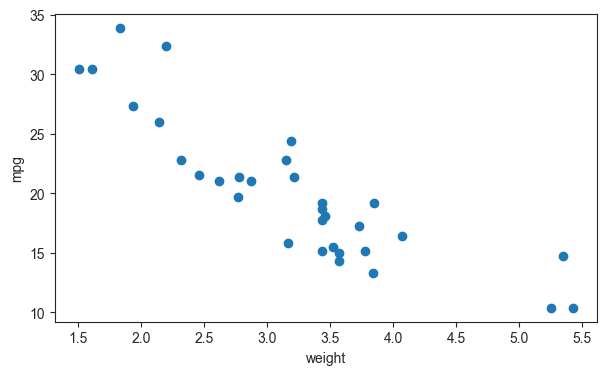

In [3]:
# Die relevanten Variablen als Streudiagramm darstellen
plt.scatter(cars["weight"], cars["mpg"])
plt.xlabel("weight")
plt.ylabel("mpg");

>**Wenn du dir nur die Grafik ansiehst: Was schätzt du für den Achsenabschnitt und die Steigung?**
>* Achsenabschnitt:
> * Steigung:

<br>

<details><summary>
Zeig mir die Antwort
</summary>

- **Achsenabschnitt**: Der `mpg`-Wert eines Autos mit einem Gewicht von 0 läge bei etwa 40 (praktisch nicht sinnvoll).
- **Steigung**: Mit jeder Zunahme von `weight` um 1 Einheit sinkt `mpg  ` um etwa **5-6 mpg**.
</details>

--- 
## Einfache lineare Regression mit scikit-learn



In diesem Abschnitt trainieren wir unser erstes lineares Regressionsmodell mit der Bibliothek scikit-learn. Bisher haben wir immer von Antwortvariablen und erklärenden Variablen gesprochen. In Data Science ist es viel üblicher, die Antwortvariable, also die Variable, die wir vorhersagen wollen, als **Zielvariable (Target)** zu bezeichnen. Die erklärenden Variablen heißen meist einfach **Features**. Außerdem werden die Steigung(en) oft als Regressions-**Koeffizient(en)** (coefficients) bezeichnet.

Scikit-learn macht es uns leicht, seine Algorithmen zu nutzen, solange wir unsere Daten so organisieren, dass wir sie in die Modelle geben können.
Deshalb legen wir im ersten Schritt die Zielvariable (`mpg`) und das Feature (`weight`) fest. Nachdem wir ein `LinearRegression`-Objekt instanziiert haben, können wir es trainieren, indem wir die Methode `.fit` mit unseren Daten aufrufen.

Beachte, dass `"miles per gallon"` der Kehrwert des in Deutschland verbreiteten `"litres per kilometer"` ist.

In [4]:
# Lineare Regression aus der sklearn-Bibliothek importieren
from sklearn.linear_model import LinearRegression

In [5]:
# Daten für die Modellierung vorbereiten: Target und Feature festlegen
X = cars[["weight"]]  # X muss 2-dimensional sein, deshalb brauchen wir hier doppelte eckige Klammern
y = cars["mpg"]

In [6]:
# Dimensionen von X anzeigen
X.shape

(32, 1)

In [7]:
# Unser Modell instanziieren
lin_reg = LinearRegression()

# Das Modell mit unseren Daten trainieren
lin_reg.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-5.34]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['weight']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,37.29
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


In [8]:
# Achsenabschnitt und Steigung/Koeffizient erreichst du über .intercept_ und .coef_
intercept = lin_reg.intercept_
slope = lin_reg.coef_[0]
print("Model intercept:", intercept)
print("Coefficient for feature weight:", slope)

Model intercept: 37.28512616734204
Coefficient for feature weight: -5.344471572722678


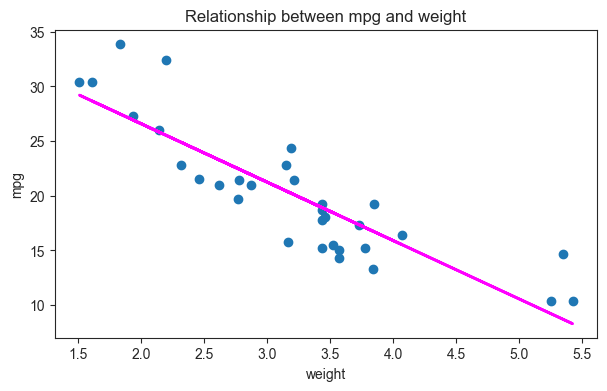

In [9]:
# Unsere Datenpunkte plotten
plt.scatter(X, y)

# Die angepasste Regressionsgerade unseres Modells hinzufügen
plt.plot(X, X * slope + intercept, "-", color="magenta", linewidth=2)

plt.title("Relationship between mpg and weight")
plt.ylabel("mpg")
plt.xlabel("weight");

In den Zellen oben haben wir das lineare Regressionsmodell auf unseren Daten trainiert. Mit den Werten für Achsenabschnitt und Koeffizient konnten wir die Regressionsgerade in das Streudiagramm unserer Daten einzeichnen.

Wir können auch den Achsenabschnitt unseres Modells interpretieren: Laut Modell läge `mpg` eines Autos mit einem `weight` von 0 bei ~ 37.28. Wie unser Fall zeigt, können Achsenabschnitte in der "echten Welt" eine Bedeutung haben, müssen es aber nicht. Ein Auto mit einem Gewicht von 0 kann es nicht geben ...

Der Wert des Koeffizienten sagt uns, dass wir eine Veränderung von `mpg` um ~ -5.34 erwarten würden, wenn `weight` um 1 steigt. 

### Die Anpassungsgüte des Modells quantifizieren




Bisher haben wir gesehen, wie man die Koeffizienten eines einfachen linearen Regressionsmodells schätzt. Was uns noch fehlt, ist ein sauberer Weg, um zu bewerten, ob unser Modell gute Arbeit geleistet hat oder kompletter Murks ist. Solange wir nur ein Feature haben, können wir die Regressionsgerade in unsere Daten zeichnen, um ein Gefühl für die Anpassung (fit) zu bekommen. Sobald wir aber mehr Features verwenden, haben wir zu viele Dimensionen zum Plotten. Und ohnehin sind Plotten und Augenmaß eine ziemlich ungenaue Art, etwas zu messen.

#### $R^2$ (Bestimmtheitsmaß, r-squared)


Zum Glück gibt es einen Weg, die Anpassung unseres Modells numerisch zu bewerten. Wir können das $R^2$ des Modells berechnen. Es lässt sich einfach interpretieren: $R^2$ ist der *Anteil* der Varianz der Zielvariablen (bei uns mpg), der durch unsere Features erklärt werden kann (bei uns gibt es nur ein Feature: weight).

Mathematisch können wir $R^2$ so definieren:

$$R^2 = 1 - \frac{SSR}{SST}$$

wobei **SSR** die Summe der quadrierten Residuen (sum of squared residuals, $\sum_{i=1}^n e_i^2$) und **SST** die Gesamtquadratsumme (total sum of squares, $\sum_{i=1}^n (y_i - \bar{y})^2$) ist.

Der Wert für $R^2$ kann zwischen 0 und 1 liegen. Wenn das Modell die Daten perfekt abbildet, ist **SSR** gleich 0 und $R^2$ ergibt 1. Umgekehrt führt eine schlechte Anpassung an die Daten zu einer hohen **SSR**, und $R^2$ wird niedrig sein oder sogar gegen 0 gehen.

#### $R^2$ in scikit-learn


Wir müssen $R^2$ nicht von Hand berechnen. Es ist bereits in sklearn implementiert, und wir können es aus dem Modul `sklearn.metrics` importieren. Wenn du in der [sklearn-Dokumentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html) die Funktion `r2_score` nachschlägst, siehst du, dass du mindestens zwei Argumente übergeben musst: *y_true* und *y_pred*.
* *y_true* sind die "wahren" Werte unserer Zielvariablen (bei uns in der Variablen `y` gespeichert).
* *y_pred* sind die geschätzten Zielwerte. Wir haben sie am Anfang des Notebooks $\hat{y}$ genannt. Wir könnten sie über Steigung und Achsenabschnitt berechnen, aber sklearn bietet uns dafür eine bequemere Methode namens `.predict`.  

In [10]:
# R-Quadrat (r-squared) aus sklearn importieren
from sklearn.metrics import r2_score

In [11]:
# Den geschätzten Wert für jeden Datenpunkt berechnen
y_hat = lin_reg.predict(X)

# Das R-Quadrat für unser Modell berechnen
print("R-squared:", round(r2_score(y, y_hat), 3))

R-squared: 0.753


Ein $R^2$ von 0.753 klingt zunächst gut, aber du solltest dich nicht allein auf dieses Maß verlassen, wenn es darum geht, die Korrektheit deines Modells zu beurteilen. Ein $R^2$ von 0.753 bedeutet "nur", dass unser Feature `weight` 75.3 % der Varianz unserer Zielvariablen `mpg` erklärt.

Wie man die Leistung (performance) eines Modells richtig bewertet, schauen wir uns in einer späteren Session genauer an.

### Vorhersagen für neue Beobachtungen



Einer der Gründe, warum wir in Data Science Modelle trainieren, ist natürlich, Vorhersagen für neue Beobachtungen zu treffen.
Im Abschnitt oben haben wir die Methode `.predict` schon genutzt, um die geschätzten y-Werte für die Daten zu berechnen, mit denen wir unser Modell trainiert haben. Damit konnten wir das $R^2$ des Modells berechnen.

Wir können `.predict` auch nutzen, um für eine neue Beobachtung einen Wert unserer Zielvariablen zu schätzen (oder vorherzusagen). In unserem Fall heißt das: Wir können den geschätzten `mpg`-Wert für ein Auto mit einem bisher unbekannten Gewicht berechnen. Um Fehler oder Warnungen zu vermeiden, müssen wir sicherstellen, dass unser neuer Datenpunkt dasselbe Format hat wie die Daten, mit denen wir das Modell trainiert haben. Deshalb legen wir einen winzigen DataFrame mit einer Spalte namens `weight` und einem Eintrag an. 

In [12]:
# Den mpg-Wert für ein neues Auto mit einem Gewicht von 4.5 vorhersagen
new_car = pd.DataFrame({"weight": [4.5]})
y_hat_new = lin_reg.predict(new_car)

In [13]:
print("Predicted value for new observation:", y_hat_new[0].round(3))

Predicted value for new observation: 13.235


Laut unserem Modell hätte ein Auto mit einem Gewicht von 4.5 einen Kraftstoffverbrauch von 13.235 mpg. 

## Zusammenfassung



- Lineare Regression bedeutet, die am besten passende Gerade für die Daten zu finden.
- Einfache lineare Regression umfasst eine Zielvariable und nur **ein** Feature. Multiple lineare Regression umfasst mehr als ein Feature.
- Lineare Regression kann eine Beziehung annähern, aber keine Kausalität beweisen.
- Lineare Regression trifft einige **Annahmen**: Linearität, Fehler mit Mittelwert null, strikte Exogenität, Homoskedastizität und keine Multikollinearität.
- Die Methode der kleinsten Quadrate (OLS) ist ein Anpassungsverfahren (fitting algorithm), das mathematisch die beste Lösung findet.
- $\textbf{R}^2$ ist der Anteil der Variation, der durch das Modell erklärt wird.